# Test 0: Pre-reconstruction 2PCF multipoles

## Aim
Measure the pre-reconstruction correlation-function multipoles for 10
independent simulations with the same ΛCDM cosmology. The requested
separation range is 0–200 Mpc/h, with bins of width 5 Mpc/h.

## Catalogue choice
We will start with the standard Quijote `fiducial` simulations
(realizations 0–9). This set has zero neutrino mass and uses 2LPT
initial conditions. We will use the Friends-of-Friends (FoF) halo
catalogue at snapshot 003, corresponding to z = 0.5. Quijote's
standard box is 1000 Mpc/h on each side.

References:
- [Quijote simulation types](https://quijote-simulations.readthedocs.io/en/latest/types.html)
- [Quijote FoF catalogue guide](https://quijote-simulations.readthedocs.io/en/latest/halos.html)

## Step 1: Prepare and locate the catalogue
We created the NERSC scratch destination for realization 0 and checked
for `group_tab_003.*` files. The check found zero files. Therefore,
the catalogue has not yet been transferred; no halo measurement has
been made.

In [3]:
from pathlib import Path
import os

scratch = Path(os.environ["SCRATCH"])
catalogue = scratch / "Quijote/Halos/FoF/fiducial/0/groups_003"
parts = sorted(catalogue.glob("group_tab_003.*"))

print("NERSC scratch:", scratch)
print("First catalogue directory:", catalogue)
print("Catalogue parts found:", len(parts))
for part in parts:
    print(part.name)

NERSC scratch: /pscratch/sd/m/mawais
First catalogue directory: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003
Catalogue parts found: 1
group_tab_003.0


In [4]:
from pathlib import Path

destination = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003")
destination.mkdir(parents=True, exist_ok=True)
print(destination)

/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003


## Step 2: Transfer the first FoF halo catalogue

The destination directory on NERSC is
`/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003/`.

It currently contains no `group_tab_003.*` files. We will transfer
the FoF halo catalogue for fiducial realization 0, snapshot 003
(z = 0.5), before attempting to read or measure it. We will check
one realization first, then extend the procedure to 10.

In [5]:
from pathlib import Path

folder = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003")
parts = sorted(folder.glob("group_tab_003.*"))

print("Catalogue parts found:", len(parts))
for part in parts:
    print(part.name, f"{part.stat().st_size / 1024**2:.2f} MiB")

Catalogue parts found: 1
group_tab_003.0 24.81 MiB


## Step 2: Verify the transferred FoF catalogue

Globus reports that the first catalogue file was transferred successfully.
Here we check that it is present in NERSC scratch before reading any halo data.

In [6]:
from pathlib import Path

folder = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003")
parts = sorted(folder.glob("group_tab_003.*"))

print("Catalogue directory:", folder)
print("Catalogue parts found:", len(parts))

for part in parts:
    print(part.name, part.stat().st_size, "bytes")

Catalogue directory: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003
Catalogue parts found: 1
group_tab_003.0 26018184 bytes


## Step 3: Set up the FoF catalogue reader

The catalogue file is present. This notebook's Python environment could not
previously import `readfof`, so we obtain the reader from the official Pylians3
repository and record which copy we use.

In [7]:
from pathlib import Path
from urllib.request import urlopen
import sys

reader_dir = Path.home() / "quijote_tools"
reader_dir.mkdir(exist_ok=True)
reader_file = reader_dir / "readfof.py"

if not reader_file.exists():
    url = "https://raw.githubusercontent.com/franciscovillaescusa/Pylians3/master/library/readfof.py"
    with urlopen(url, timeout=30) as response:
        reader_file.write_bytes(response.read())

sys.path.insert(0, str(reader_dir))
import readfof

print("FoF reader:", readfof.__file__)

FoF reader: /global/homes/m/mawais/quijote_tools/readfof.py


## Step 4: Read the first halo catalogue

We read realization 0 at snapshot 003. We do not request particle IDs because
this step needs only halo properties. We print the halo count and the ranges of
positions and masses to check that the catalogue was interpreted correctly.

In [8]:
import numpy as np

snapdir = "/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0"

fof = readfof.FoF_catalog(
    snapdir, 3,
    long_ids=False, swap=False, SFR=False, read_IDs=False
)

positions = np.asarray(fof.GroupPos) / 1e3     # Mpc/h
masses = np.asarray(fof.GroupMass) * 1e10       # Msun/h
particles = np.asarray(fof.GroupLen)

print("Total FoF halos:", len(particles))
print("Halos with at least 20 particles:", np.count_nonzero(particles >= 20))
print("Particle count range:", particles.min(), "to", particles.max())
print("Position range [Mpc/h]:", positions.min(), "to", positions.max())
print("Mass range [Msun/h]:", masses.min(), "to", masses.max())

Total FoF halos: 309740
Halos with at least 20 particles: 309740
Particle count range: 20 to 3189
Position range [Mpc/h]: 1.6815186e-05 to 999.99646
Mass range [Msun/h]: 1.3131216e+13 to 2.0937775e+15


## Step 5: Define the halo sample and line of sight

We use the Quijote fiducial realization 0 at z = 0.5 in a periodic
1000 Mpc/h box. For this initial check, we retain all FoF halos
(20 or more particles) and report their number density. We create
a separate redshift-space position array by shifting the z coordinate
with each halo's line-of-sight peculiar velocity; the original
real-space positions remain available for comparison.

The mass selection and line-of-sight convention will be held fixed
for every realization in Test 0.

In [9]:
import numpy as np
from importlib.util import find_spec

boxsize = 1000.0                   # Mpc/h
redshift = 0.5
omega_m = 0.3175                   # Quijote fiducial
omega_lambda = 1.0 - omega_m       # flat, massless-neutrino fiducial model
los_axis = 2                      # z axis

# H(z)/h has units km/s/(Mpc/h).
hubble_over_h = 100.0 * np.sqrt(
    omega_m * (1.0 + redshift)**3 + omega_lambda
)

real_positions = np.asarray(positions, dtype=np.float64)
physical_velocities = np.asarray(fof.GroupVel, dtype=np.float64) * (1.0 + redshift)

redshift_positions = real_positions.copy()
displacement = (
    (1.0 + redshift) * physical_velocities[:, los_axis] / hubble_over_h
)
redshift_positions[:, los_axis] = (
    real_positions[:, los_axis] + displacement
) % boxsize

assert real_positions.shape == physical_velocities.shape
assert np.isfinite(redshift_positions).all()
assert ((redshift_positions >= 0) & (redshift_positions < boxsize)).all()

separation_edges = np.arange(0.0, 205.0, 5.0)  # 40 bins, edges 0 through 200

print("Halos retained:", len(real_positions))
print("Number density [(h/Mpc)^3]:", len(real_positions) / boxsize**3)
print("H(z)/h [km/s/(Mpc/h)]:", hubble_over_h)
print("Line of sight: z axis")
print("Absolute z displacement, median/max [Mpc/h]:",
      np.median(np.abs(displacement)), np.max(np.abs(displacement)))
print("Separation bins:", len(separation_edges) - 1)
print("pycorr available:", find_spec("pycorr") is not None)
print("Corrfunc available:", find_spec("Corrfunc") is not None)

Halos retained: 309740
Number density [(h/Mpc)^3]: 0.00030974
H(z)/h [km/s/(Mpc/h)]: 132.44102461095656
Line of sight: z axis
Absolute z displacement, median/max [Mpc/h]: 2.2781620237531657 23.519658127077907
Separation bins: 40
pycorr available: True
Corrfunc available: True


## Step 6: Measure pre-reconstruction 2PCF multipoles for realization 0

We count halo pairs in redshift space using periodic boundaries and the
z axis as the line of sight. Separation edges run from 0 to 200 Mpc/h
in steps of 5 Mpc/h. We project the result onto multipoles ell = 0, 2, 4.
This is the pre-reconstruction measurement: no reconstruction has been
applied to the halo positions.

In [13]:
from pathlib import Path
import sys
import numpy as np
from pycorr import TwoPointCorrelationFunction

# 1. Load the FoF reader downloaded earlier.
reader_dir = Path.home() / "quijote_tools"
if not (reader_dir / "readfof.py").is_file():
    raise FileNotFoundError(f"FoF reader not found: {reader_dir / 'readfof.py'}")

sys.path.insert(0, str(reader_dir))
import readfof

# 2. Read Quijote fiducial realization 0 at snapshot 003 (z = 0.5).
snapdir = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0")
catalogue_file = snapdir / "groups_003" / "group_tab_003.0"
if not catalogue_file.is_file():
    raise FileNotFoundError(f"Catalogue not found: {catalogue_file}")

fof = readfof.FoF_catalog(
    str(snapdir), 3,
    long_ids=False, swap=False, SFR=False, read_IDs=False
)

# 3. Keep FoF halos with at least 20 particles.
keep = np.asarray(fof.GroupLen) >= 20
positions_real = np.asarray(fof.GroupPos[keep], dtype=np.float64) / 1e3
velocities = np.asarray(fof.GroupVel[keep], dtype=np.float64) * 1.5

# 4. Shift the z coordinate into redshift space and wrap it into the box.
boxsize = 1000.0  # Mpc/h
redshift = 0.5
omega_m = 0.3175
hubble_over_h = 100.0 * np.sqrt(
    omega_m * (1.0 + redshift)**3 + (1.0 - omega_m)
)

positions_rsd = positions_real.copy()
positions_rsd[:, 2] = (
    positions_real[:, 2]
    + (1.0 + redshift) * velocities[:, 2] / hubble_over_h
) % boxsize

assert positions_rsd.shape[1] == 3
assert np.isfinite(positions_rsd).all()
assert ((positions_rsd >= 0) & (positions_rsd < boxsize)).all()

# 5. Measure the pre-reconstruction 2PCF with periodic boundaries.
s_edges = np.arange(0.0, 205.0, 5.0)  # 40 bins from 0 to 200 Mpc/h
mu_edges = np.linspace(-1.0, 1.0, 201)

print("Halos used:", len(positions_rsd))
print("Number density [(h/Mpc)^3]:", len(positions_rsd) / boxsize**3)
print("Starting periodic pair count...", flush=True)

result_0 = TwoPointCorrelationFunction(
    "smu",
    (s_edges, mu_edges),
    data_positions1=positions_rsd,
    position_type="pos",  # one array with shape (N, 3)
    boxsize=boxsize,
    los="z",
    engine="corrfunc",
    nthreads=4,
)

# 6. Obtain and save monopole, quadrupole, and hexadecapole.
s, xi = result_0.get_corr(return_sep=True, ells=(0, 2, 4))
s = np.asarray(s)
xi = np.asarray(xi)

print("Separation shape:", s.shape)
print("Multipole shape:", xi.shape)

if xi.shape != (3, 40):
    raise RuntimeError(f"Unexpected multipole shape: {xi.shape}")

for ell, values in zip((0, 2, 4), xi):
    print(f"ell={ell}: {np.isfinite(values).sum()}/40 finite bins")

output_dir = Path("/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon")
output_dir.mkdir(parents=True, exist_ok=True)
output_file = output_dir / "fiducial_0_snap003_xi_rsd.npz"

np.savez_compressed(
    output_file,
    s=s,
    xi0=xi[0],
    xi2=xi[1],
    xi4=xi[2],
    s_edges=s_edges,
    mu_edges=mu_edges,
    n_halos=len(positions_rsd),
    boxsize=boxsize,
    redshift=redshift,
    min_particles=20,
)

print("Saved:", output_file)

Halos used: 309740
Number density [(h/Mpc)^3]: 0.00030974
Starting periodic pair count...
Separation shape: (40,)
Multipole shape: (3, 40)
ell=0: 40/40 finite bins
ell=2: 40/40 finite bins
ell=4: 40/40 finite bins
Saved: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_xi_rsd.npz


## Step 7: Inspect the pre-reconstruction 2PCF

We load the saved measurement for fiducial realization 0 and plot
s²ξ₀(s), s²ξ₂(s), and s²ξ₄(s). This checks the shape of the measured
multipoles before applying the same procedure to nine more mocks.
A single realization is not used to claim a BAO detection.

Loaded: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_xi_rsd.npz
Halos: 309740
Separation range [Mpc/h]: 3.4119397477530327 to 197.5209390274295


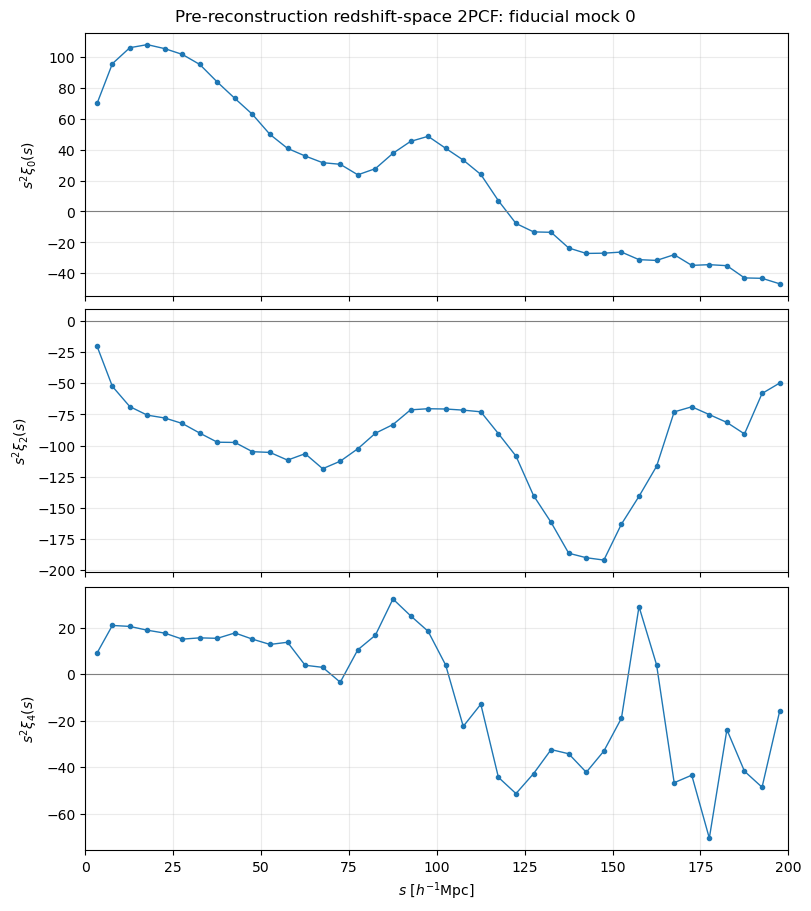

Saved plot: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_xi_rsd.png


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

measurement_file = Path(
    "/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/"
    "fiducial_0_snap003_xi_rsd.npz"
)

with np.load(measurement_file, allow_pickle=False) as data:
    s = data["s"]
    multipoles = [data["xi0"], data["xi2"], data["xi4"]]
    n_halos = int(data["n_halos"])

assert s.shape == (40,)
assert all(values.shape == (40,) for values in multipoles)
assert all(np.isfinite(values).all() for values in multipoles)

print("Loaded:", measurement_file)
print("Halos:", n_halos)
print("Separation range [Mpc/h]:", s.min(), "to", s.max())

fig, axes = plt.subplots(
    3, 1, figsize=(8, 9), sharex=True, constrained_layout=True
)

for ax, ell, values in zip(axes, (0, 2, 4), multipoles):
    ax.plot(s, s**2 * values, "o-", markersize=3, linewidth=1)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_ylabel(fr"$s^2\xi_{{{ell}}}(s)$")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel(r"$s\ [h^{-1}\mathrm{Mpc}]$")
axes[-1].set_xlim(0, 200)
fig.suptitle("Pre-reconstruction redshift-space 2PCF: fiducial mock 0")

plot_file = measurement_file.with_suffix(".png")
fig.savefig(plot_file, dpi=180)
plt.show()

print("Saved plot:", plot_file)

Saved fields: ['s', 'xi0', 'xi2', 'xi4', 's_edges', 'mu_edges', 'n_halos', 'boxsize', 'redshift', 'min_particles']
Halos: 309740
Audit passed: 40 finite bins for each of ell = 0, 2, 4.
First/last measured separations: 3.4119397477530327 197.5209390274295
First/last bin intervals: (np.float64(0.0), np.float64(5.0)) (np.float64(195.0), np.float64(200.0))


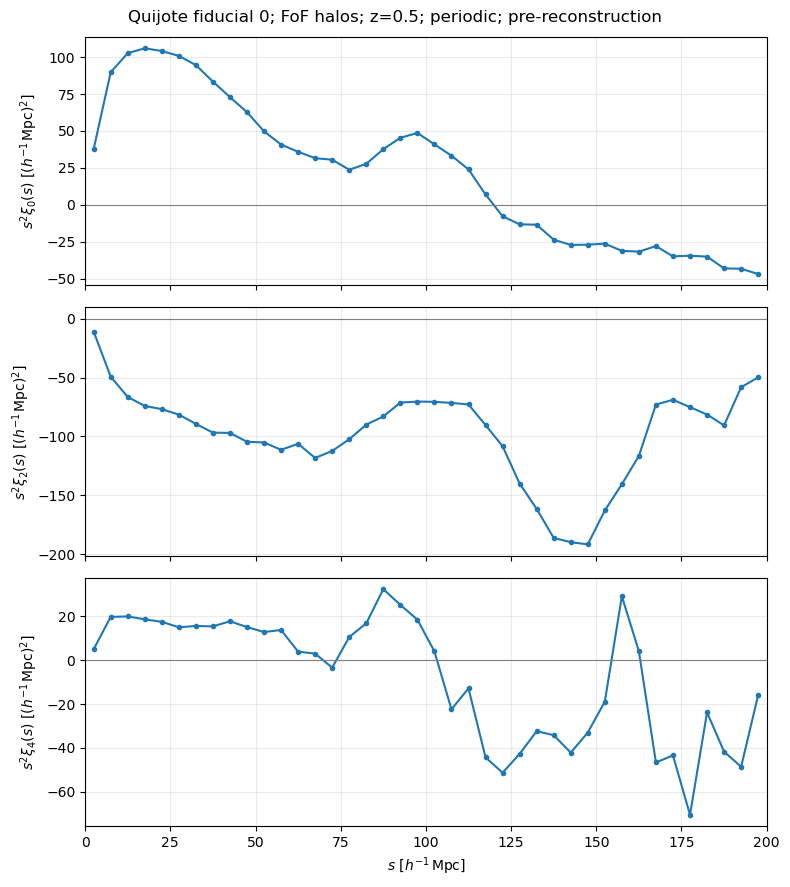

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

path = Path(
    "/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/"
    "fiducial_0_snap003_xi_rsd.npz"
)

with np.load(path, allow_pickle=False) as saved:
    print("Saved fields:", saved.files)

    s = np.asarray(saved["s"])
    xi = np.stack([saved[f"xi{ell}"] for ell in (0, 2, 4)])

    edge_key = next(
        (key for key in ("s_edges", "separation_edges")
         if key in saved.files),
        None,
    )
    if edge_key is None:
        raise KeyError("Separation edges were not saved; inspect the measurement cell.")

    s_edges = np.asarray(saved[edge_key])
    mu_edges = np.asarray(saved["mu_edges"])

    if "n_halos" in saved.files:
        print("Halos:", int(saved["n_halos"]))

assert s.shape == (40,), f"Unexpected separation shape: {s.shape}"
assert xi.shape == (3, 40), f"Unexpected multipole shape: {xi.shape}"
assert np.all(np.isfinite(s)) and np.all(np.isfinite(xi))
assert np.allclose(s_edges, np.arange(0., 205., 5.))
assert np.allclose(mu_edges, np.linspace(-1., 1., 201))
assert np.all((s >= s_edges[:-1]) & (s <= s_edges[1:]))

print("Audit passed: 40 finite bins for each of ell = 0, 2, 4.")
print("First/last measured separations:", s[0], s[-1])
print("First/last bin intervals:",
      (s_edges[0], s_edges[1]),
      (s_edges[-2], s_edges[-1]))

# Use identical horizontal coordinates for every realization later.
s_center = (s_edges[:-1] + s_edges[1:]) / 2

fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
for ax, ell, values in zip(axes, (0, 2, 4), xi):
    ax.plot(s_center, s_center**2 * values, "o-", ms=3)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_ylabel(
        rf"$s^2\xi_{{{ell}}}(s)$ "
        r"$[(h^{-1}\,\mathrm{Mpc})^2]$"
    )
    ax.grid(alpha=0.25)

axes[-1].set_xlabel(r"$s\ [h^{-1}\,\mathrm{Mpc}]$")
axes[-1].set_xlim(0, 200)
fig.suptitle("Quijote fiducial 0; FoF halos; z=0.5; periodic; pre-reconstruction")
fig.tight_layout()
plt.show()

## Velocity/RSD check: pilot realization 0

checking whether the growth rate inferred from the simulation's
velocity-induced redshift-space distortions agrees with its input cosmology.

We use the same FoF halos at snapshot 003 (z = 0.5) in two forms: their original
real-space positions and positions displaced along the z line of sight by their
peculiar velocities. We measure periodic-box power-spectrum multipoles for both.

On sufficiently large scales, the linear Kaiser model is

$$
P_{\rm real}(k)=b^2P_m(k),\qquad
P_{\rm RSD}(k,\mu_k)=(b+f\mu_k^2)^2P_m(k).
$$

Here b is halo bias, f is the linear growth rate, and P_m is the linear matter
power spectrum. We fit the real-space monopole and the redshift-space monopole
and quadrupole for b and f. We repeat the fit with different maximum
wavenumbers to see whether the answer is stable.

The Quijote fiducial cosmology predicts f(z=0.5) ≈ 0.762579 using
f ≈ Ω_m(z)^0.55. This is a prediction; the fit below is our first estimate
from the mock. A result from one box without a validated covariance is a
pilot diagnostic, not a final constraint or a BAO-versus-RSD comparison.

In [3]:
from pathlib import Path
import numpy as np
from scipy.optimize import least_squares
from pypower import CatalogFFTPower
from cosmoprimo import Cosmology
import sys
from pathlib import Path

tools_dir = Path.home() / "quijote_tools"
matches = sorted(tools_dir.rglob("readfof.py")) if tools_dir.is_dir() else []

if not matches:
    raise FileNotFoundError(
        f"Cannot find readfof.py under {tools_dir}. "
        "Tell me where you saved Pylians/readfof.py."
    )

sys.path.insert(0, str(matches[0].parent))
import readfof

print("Using readfof from:", readfof.__file__)

# 1. Read the same realization and halo selection as our 2PCF pilot.
z = 0.5
L = 1000.0                         # Mpc/h
omega_m0 = 0.3175
catalogue = Path(
    "/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0"
)

part = catalogue / "groups_003" / "group_tab_003.0"
if not part.is_file():
    raise FileNotFoundError(part)

fof = readfof.FoF_catalog(
    str(catalogue), 3,
    long_ids=False, swap=False, SFR=False, read_IDs=False,
)
keep = np.asarray(fof.GroupLen) >= 20

real_pos = np.asarray(fof.GroupPos[keep], dtype=np.float64) / 1000.0
v_pec = (1.0 + z) * np.asarray(fof.GroupVel[keep], dtype=np.float64)

if len(real_pos) != 309740:
    raise RuntimeError(
        f"Expected 309740 halos in realization 0; found {len(real_pos)}"
    )

# Quijote convention: v_pec is in km/s; H_h is km/s per (Mpc/h).
# The comoving RSD displacement is v_z / (a H_h).
H_h = 100.0 * np.sqrt(
    omega_m0 * (1.0 + z)**3 + 1.0 - omega_m0
)
dz = (1.0 + z) * v_pec[:, 2] / H_h

rsd_pos = real_pos.copy()
rsd_pos[:, 2] = (rsd_pos[:, 2] + dz) % L
real_pos %= L

print("Halos:", len(real_pos))
print("Median/max |z displacement| [Mpc/h]:",
      np.median(np.abs(dz)), np.max(np.abs(dz)))

# 2. Measure real-space and redshift-space power multipoles.
# These Fourier k bins are for the RSD check; they do not change
# the 0–200 Mpc/h separation bins of the earlier 2PCF.
k_edges = np.arange(0.005, 0.105 + 1e-9, 0.01)  # h/Mpc
settings = dict(
    edges=k_edges,
    ells=(0, 2, 4),
    los="z",
    boxsize=L,
    boxcenter=(L / 2, L / 2, L / 2),
    nmesh=256,
    resampler="tsc",
    interlacing=2,
    position_type="pos",
    wrap=True,
    dtype="f4",
)

real_poles = CatalogFFTPower(
    data_positions1=real_pos, **settings
).poles
rsd_poles = CatalogFFTPower(
    data_positions1=rsd_pos, **settings
).poles

k = np.asarray(real_poles.k)
if not np.allclose(k, rsd_poles.k):
    raise RuntimeError("Real-space and RSD k bins differ")

# pypower subtracts its estimated auto-catalogue shot noise here.
Pr = np.asarray(
    real_poles.get_power(remove_shotnoise=True, complex=False)
)
Ps = np.asarray(
    rsd_poles.get_power(remove_shotnoise=True, complex=False)
)

if Pr.shape != (3, len(k)) or Ps.shape != Pr.shape:
    raise RuntimeError(f"Unexpected power shapes: {Pr.shape}, {Ps.shape}")
if not (np.isfinite(Pr).all() and np.isfinite(Ps).all()):
    raise RuntimeError("Non-finite measured power")

# 3. Build a normalized linear matter template at z=0.5.
# sigma8=0.834 is the Quijote fiducial value at z=0.
cosmo = Cosmology(
    h=0.6711,
    Omega_m=0.3175,
    Omega_b=0.049,
    n_s=0.9624,
    sigma8=0.834,
    m_ncdm=0.0,
    engine="class",
)
Pm = np.asarray(
    cosmo.get_fourier().pk_interpolator().to_1d(z=z)(k)
)
if Pm.shape != k.shape or not np.all(Pm > 0):
    raise RuntimeError("Invalid linear matter-power template")

omega_m_z = (
    omega_m0 * (1 + z)**3
    / (omega_m0 * (1 + z)**3 + 1 - omega_m0)
)
f_pred = omega_m_z**0.55

# 4. Fit b and f using P0(real), P0(RSD), and P2(RSD).
# P4 is retained as an independent diagnostic, not fitted.
def kaiser_amplitudes(b, f):
    return np.array([
        b*b,
        b*b + (2/3)*b*f + (1/5)*f*f,
        (4/3)*b*f + (4/7)*f*f,
    ])

def fit_range(kmax):
    use = (k >= 0.02) & (k <= kmax)
    if use.sum() < 3:
        raise RuntimeError("Too few Fourier bins in fit range")

    measured = np.stack([
        Pr[0, use], Ps[0, use], Ps[1, use]
    ]) / Pm[use]

    b_initial = np.sqrt(np.median(Pr[0, use] / Pm[use]))
    if not np.isfinite(b_initial) or b_initial <= 0:
        raise RuntimeError("Could not initialize halo bias")

    def residual(parameters):
        predicted = kaiser_amplitudes(*parameters)[:, None]
        return (predicted - measured).ravel()

    fit = least_squares(
        residual,
        x0=(float(b_initial), f_pred),
        bounds=([0.1, 0.0], [10.0, 2.0]),
    )
    if not fit.success:
        raise RuntimeError(fit.message)

    return fit.x, int(use.sum())

print(f"Predicted f at z=0.5: {f_pred:.6f}")
print("Pilot fits (no statistical error assigned):")

fits = []
for kmax in (0.06, 0.08, 0.10):
    (b_fit, f_fit), n_bins = fit_range(kmax)
    fits.append((kmax, b_fit, f_fit))
    print(
        f"0.02 <= k <= {kmax:.2f} h/Mpc: "
        f"b={b_fit:.4f}, f={f_fit:.4f}, "
        f"beta=f/b={f_fit/b_fit:.4f}; {n_bins} k bins"
    )

# Keep the diagnostic output separate from the existing 2PCF archive.
output = Path(
    "/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon"
)
output.mkdir(parents=True, exist_ok=True)
filename = output / "fiducial_0_growth_rsd_pilot.npz"
np.savez_compressed(
    filename,
    k=k, k_edges=k_edges,
    power_real=Pr, power_rsd=Ps, linear_matter_power=Pm,
    fits=np.asarray(fits), f_pred=f_pred,
    n_halos=len(real_pos), redshift=z, boxsize=L,
)
print("Saved:", filename)

Using readfof from: /global/homes/m/mawais/quijote_tools/readfof.py
Halos: 309740
Median/max |z displacement| [Mpc/h]: 2.2781620237531657 23.519658127077907
Predicted f at z=0.5: 0.762579
Pilot fits (no statistical error assigned):
0.02 <= k <= 0.06 h/Mpc: b=1.9533, f=0.8880, beta=f/b=0.4546; 4 k bins
0.02 <= k <= 0.08 h/Mpc: b=1.9397, f=0.8733, beta=f/b=0.4502; 6 k bins
0.02 <= k <= 0.10 h/Mpc: b=1.9460, f=0.8690, beta=f/b=0.4465; 8 k bins
Saved: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_growth_rsd_pilot.npz


## Test 0, step 2: analytical covariance for one mock

Our input is the saved pre-reconstruction, redshift-space 2PCF
multipoles of Quijote fiducial realization 0 at z = 0.5.

For N = 1, the mean multipoles are the measured multipoles themselves.
We will use BeXiCov to construct an analytical covariance appropriate
for one periodic box. The box volume is (1000 Mpc/h)^3, and the halo
number density is 309740 / 1000^3 = 0.00030974 (h/Mpc)^3.

We retain all measured bins from 0 to 200 Mpc/h as the source data.
The published BeXiCov workflow calibrates the covariance model over
10–200 Mpc/h. The subsequent pre-reconstruction BAO fit uses
50–150 Mpc/h, with 20 bins for each of xi_0, xi_2, and xi_4.

This step prepares and checks the input. A covariance or BAO result
will be reported only after its software run and output checks pass.

Method: https://arxiv.org/pdf/2605.03446 (Sections 5.1–5.2)

In [4]:
from pathlib import Path
import numpy as np

source = Path(
    "/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/"
    "fiducial_0_snap003_xi_rsd.npz"
)

with np.load(source, allow_pickle=False) as data:
    edges = np.asarray(data["s_edges"], dtype=float)
    xi = np.stack(
        [np.asarray(data[f"xi{ell}"], dtype=float) for ell in (0, 2, 4)]
    )
    n_halos = int(np.asarray(data["n_halos"]).item())
    boxsize = float(np.asarray(data["boxsize"]).item())
    redshift = float(np.asarray(data["redshift"]).item())
    measured_s = np.asarray(data["s"], dtype=float)

assert np.array_equal(edges, np.arange(0.0, 205.0, 5.0))
assert xi.shape == (3, 40)
assert measured_s.shape == (40,)
assert np.isfinite(xi).all()
assert n_halos == 309740
assert np.isclose(boxsize, 1000.0)
assert np.isclose(redshift, 0.5)

centres = (edges[:-1] + edges[1:]) / 2
cov_bins = (edges[:-1] >= 10) & (edges[1:] <= 200)
fit_bins = (edges[:-1] >= 50) & (edges[1:] <= 150)

assert cov_bins.sum() == 38
assert fit_bins.sum() == 20

volume = boxsize**3
nbar = n_halos / volume

# For one mock, its measured xi is also the one-mock mean.
# Keep all 40 bins; the software's documented interface will determine
# how its covariance and BAO fitting ranges are selected.
table = source.with_name("fiducial_0_snap003_xi_input.txt")
np.savetxt(
    table,
    np.column_stack((centres, xi[0], xi[1], xi[2])),
    header="s_bin_centre_Mpc_over_h xi0 xi2 xi4",
)

print("Source:", source)
print("Prepared table:", table)
print("Multipoles:", xi.shape)
print("Volume [(Mpc/h)^3]:", volume)
print("Number density [(h/Mpc)^3]:", nbar)
print("Covariance calibration bins:", cov_bins.sum(), "covering 10–200 Mpc/h")
print("BAO fit bins per multipole:", fit_bins.sum(), "covering 50–150 Mpc/h")
print("BAO data-vector length:", 3 * fit_bins.sum())

Source: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_xi_rsd.npz
Prepared table: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_xi_input.txt
Multipoles: (3, 40)
Volume [(Mpc/h)^3]: 1000000000.0
Number density [(h/Mpc)^3]: 0.00030974
Covariance calibration bins: 38 covering 10–200 Mpc/h
BAO fit bins per multipole: 20 covering 50–150 Mpc/h
BAO data-vector length: 60


In [5]:
import json
from pathlib import Path

path = Path.home() / "BeXiCov" / "Example" / "Main routines.ipynb"
notebook = json.loads(path.read_text())

shown = 0
for index, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        print(f"\n--- code cell {index} ---")
        print("".join(cell["source"])[:1800])
        shown += 1
        if shown == 12:
            break


--- code cell 1 ---
import BeXiCov.Covariance as BeXiCov
import numpy as np

--- code cell 2 ---

#------- ThCovariance ------
# Routine to compute the Gaussian covariance of the two-point correlation function (2PCF) based on Grieb et al. (2016) 
# and given the expected non-clustering signal.

# GaussianCovariance implementation from https://gitlab.com/veropalumbo.alfonso/gaussiancovariance

# Parameters:
# s: Array of separation bins
# volume: Survey volume (float)
# number_density: Sample number density
# cosmo: List of cosmological parameters (example in Models.DefaultCosmology())
# space: 'RealSpace' if the template has to be computed in real-space,
#        'RedshiftSpace' if in redshift-space
# rectype: String of reconstruction type. Leave empty for no-reconstruction,
#          'rec-sym', 'rec-iso' for the Zel'dovich reconstruction without and with RSD removal
# sigma_rec: Kernel size of rec-iso (default is 0).
#FoG_opt: boolean option for Fingers of Good, default is false

# 

In [6]:
from pathlib import Path
import importlib.util
import sys

home = Path.home()
source_dirs = (
    home / "BeXiCov",
    home / "BAOFit",
    home / "BeXiCov" / "GaussianCovariance",
)

for directory in source_dirs:
    if not directory.is_dir():
        raise FileNotFoundError(directory)
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))

packages = (
    "numpy", "scipy", "matplotlib", "camb", "hankl", "iminuit",
    "emcee", "joblib", "tensorflow", "nautilus", "astropy",
    "convo", "CosmoSampler", "GaussianCovariance",
    "BAOFit", "BeXiCov",
)

print("Notebook Python:", sys.executable)
for package in packages:
    found = importlib.util.find_spec(package) is not None
    print(f"{package:20} {'available' if found else 'MISSING'}")

Notebook Python: /global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/conda/bin/python
numpy                available
scipy                available
matplotlib           available
camb                 available
hankl                available
iminuit              available
emcee                available
joblib               available
tensorflow           available
nautilus             available
astropy              available
convo                MISSING
CosmoSampler         MISSING
GaussianCovariance   available
BAOFit               available
BeXiCov              available


### Step 2: Generate the pre-reconstruction analytical covariance

The CAMB template matches the Quijote fiducial normalization,
σ₈(z=0) = 0.834. BeXiCov returns σ₈ for the single template redshift
as a one-element array. For compatibility with the numerical integral
in this environment, we pass its scalar value to the no-wiggle model.

We use the measured ξ₀, ξ₂, and ξ₄ of realization 0, the periodic
box volume, and its halo number density. BeXiCov calibrates the
covariance over 10–200 Mpc/h. We check its dimensions, finite entries,
symmetry, and the 50–150 Mpc/h submatrix needed for the later BAO fit
before saving it. This is a one-mock pipeline check.

### Step 2c: set the Quijote fiducial model

We load the measured, unmultiplied xi_0, xi_2, and xi_4 for
realization 0. We set the Quijote fiducial cosmology at z = 0.5.
CAMB converts Quijote's sigma_8(z=0) = 0.834 into the primordial
amplitude A_s required by the fitting code.

The bias value 1.94 is only a starting value for the theoretical
covariance model, motivated by our earlier pilot power-spectrum fit.
It is not a BAO measurement.
    ### Step 2d: calculate and audit the one-mock covariance

We fit the one-mock pre-reconstruction multipoles over
10–200 Mpc/h and construct a BeXiCov covariance for the
1000 Mpc/h periodic box. We use ell = 0, 2, 4 and two
covariance iterations.

The output covariance covers all 40 measured separation bins
for each multipole, so its expected shape is 120 x 120.
Before saving it, we check finite entries, positive variances,
symmetry, and positive definiteness of the 60 x 60 submatrix
needed for the later 50–150 Mpc/h BAO fit.

In [3]:
import socket
from pathlib import Path

import numpy as np
import BeXiCov.Models as Models
from BeXiCov.Covariance import BestFitCovariance

# This calculation can be lengthy; use a NERSC CPU compute-node notebook.
host = socket.gethostname()
print("Running on:", host)
if "login" in host.lower():
    raise RuntimeError(
        "Open this notebook on a NERSC CPU compute node before running "
        "the covariance calculation."
    )

# Check the inputs prepared in cell 1.
s = np.asarray(s, dtype=float)
xi = np.asarray(xi, dtype=float)

assert s.shape == (40,)
assert xi.shape == (3, 40)
assert np.allclose(s, 2.5 + 5.0 * np.arange(40))
assert np.all(np.isfinite(xi))
assert np.isclose(volume, 1000.0**3)
assert np.isclose(nbar, 309740 / 1000.0**3)

# Keep BeXiCov's original calculation. Convert only its single-z
# sigma8 argument from a one-element array to a Python scalar.
# The guard makes this cell safe to run again in the same kernel.
if not hasattr(Models, "_original_Pk_nowiggle_one_z"):
    Models._original_Pk_nowiggle_one_z = Models.Pk_nowiggle

def _Pk_nowiggle_one_z(k, pk_linear, cosmology, sigma8, T_cmb):
    sigma8_array = np.asarray(sigma8)
    if sigma8_array.size != 1:
        raise ValueError(
            f"Expected sigma8 for one redshift; got shape "
            f"{sigma8_array.shape}"
        )
    sigma8_scalar = float(sigma8_array.reshape(-1)[0])
    if not np.isfinite(sigma8_scalar) or sigma8_scalar <= 0:
        raise ValueError(f"Invalid sigma8: {sigma8_scalar}")
    return Models._original_Pk_nowiggle_one_z(
        k, pk_linear, cosmology, sigma8_scalar, T_cmb
    )

Models.Pk_nowiggle = _Pk_nowiggle_one_z

output = Path(
    "/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/"
    "fiducial_0_snap003_bexicov_prerec.npz"
)
if output.exists():
    raise FileExistsError(
        f"{output} already exists. Inspect it before running or "
        "replacing this calculation."
    )

print("Generating the one-mock pre-reconstruction covariance...")
cov_run = BestFitCovariance(
    s=s,
    xi_ell_data=xi,
    volume=float(volume),
    number_density=float(nbar),
    cosmo=cosmo,
    space="RedshiftSpace",
    rectype="",
    sigma_rec=0.0,
    ellemax=4,
    NormCov=1,
    fit_range=[10, 200],
    Niter=2,
    Use_emu=False,
)
cov_run.run()

C_raw = np.asarray(cov_run.cov_it, dtype=float)
assert C_raw.shape == (120, 120), C_raw.shape
assert np.all(np.isfinite(C_raw))

relative_asymmetry = (
    np.max(np.abs(C_raw - C_raw.T)) / np.max(np.abs(C_raw))
)
print("Maximum relative asymmetry:", relative_asymmetry)
assert relative_asymmetry < 1e-10

# Remove only numerical round-off after the symmetry check.
C = 0.5 * (C_raw + C_raw.T)
assert np.all(np.diag(C) > 0)

fit_bins = np.flatnonzero((s >= 50) & (s <= 150))
fit_indices = np.concatenate(
    [fit_bins + ell_index * len(s) for ell_index in range(3)]
)
assert len(fit_indices) == 60

# A failed Cholesky check means this covariance should not yet be used
# for the planned BAO fit.
np.linalg.cholesky(C[np.ix_(fit_indices, fit_indices)])
assert np.all(np.isfinite(cov_run.best_fit_params))

np.savez_compressed(
    output,
    cov=C,
    s=s,
    ells=np.array([0, 2, 4]),
    volume=float(volume),
    number_density=float(nbar),
    calibration_range=np.array([10.0, 200.0]),
    planned_bao_fit_range=np.array([50.0, 150.0]),
    realization=0,
    snapshot=3,
)

print("Covariance shape:", C.shape)
print("BAO-fit submatrix shape:", C[np.ix_(fit_indices, fit_indices)].shape)
print("Saved:", output)

Running on: nid200071
Generating the one-mock pre-reconstruction covariance...
fit-range [10, 200]
considering  4  polynomials
generating theoretial covariance ...
sigma rec th 0.0
rec check 
kh for P_k_mu_models 0.0001 99.99999999999996


AttributeError: module 'numpy' has no attribute 'trapz'

### Step 3: Standard pre-reconstruction BAO fit for realization 0

We use the measured redshift-space FoF halo multipoles
\(\xi_0,\xi_2,\xi_4\) at \(z=0.5\) and the BeXiCov covariance
generated from this one mock. The separation bins are unchanged:
\(0\)–\(200\,h^{-1}\mathrm{Mpc}\), with width
\(5\,h^{-1}\mathrm{Mpc}\).

For this pilot BAO fit, we use \(50\leq s\leq150\,
h^{-1}\mathrm{Mpc}\), or 20 bins per multipole and 60 data
values in total. BAOFit fits the pre-reconstruction redshift-space
template, including the dilation parameters
\(\alpha_\parallel\) and \(\alpha_\perp\).
We check the optimizer, parameter uncertainties, fit statistic,
and model curve before saving the result. This is a pipeline test
on one realization, not a ten-mock cosmological constraint.

In [3]:
import sys
import importlib
from pathlib import Path

home = Path.home()
repo = home / "BAOFit"
expected = (repo / "BAOFit" / "Templates.py").resolve()

if not expected.is_file():
    raise FileNotFoundError(
        f"BAOFit source was not found at {expected}. "
        "Check where the repository was cloned."
    )

# Also make the previously cloned fit dependencies discoverable.
for directory in (
    home / "convo" / "src",
    home / "CosmoSampler",
    repo,
):
    if directory.is_dir() and str(directory) not in sys.path:
        sys.path.insert(0, str(directory))

# The failed import may have left the outer folder cached as BAOFit.
loaded = sys.modules.get("BAOFit")
if loaded is not None:
    package_dirs = {
        Path(p).resolve() for p in getattr(loaded, "__path__", [])
    }
    if expected.parent not in package_dirs:
        loaded_children = [
            name for name in sys.modules
            if name.startswith("BAOFit.")
        ]
        if loaded_children:
            raise RuntimeError(
                "A different BAOFit package is already active. "
                "Restart the kernel, run this path cell first, then "
                "rerun the cosmology setup and BAO fit cells."
            )
        del sys.modules["BAOFit"]

importlib.invalidate_caches()
Templates = importlib.import_module("BAOFit.Templates")
BestFit = importlib.import_module("BAOFit.Fit").BestFit

assert Path(Templates.__file__).resolve() == expected
print("Correct BAOFit module:", Templates.__file__)

cov_path = Path(
    "/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/"
    "fiducial_0_snap003_bexicov_prerec.npz"
)
print("Audited covariance file exists:", cov_path.is_file())

/global/homes/m/mawais/convo/src/convo/__init__.py:25: UserWarning: [!] Attention user: as of version 2.99.6, 'convo.e2e' (alias of 'convo.end_to_end.e2e') will ONLY return the mixing matrix, not the parameters like previous versions. Do beware!
Sorry for the inconvenience, Jacopo :)
  warnings.warn(


Correct BAOFit module: /global/homes/m/mawais/BAOFit/BAOFit/Templates.py
Audited covariance file exists: False


In [4]:
from pathlib import Path

base = Path("/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon")
expected = base / "fiducial_0_snap003_bexicov_prerec.npz"

print("Expected covariance:", expected)
print("Exists:", expected.is_file())
print("\nNPZ files currently in the output directory:")
for path in sorted(base.glob("*.npz")):
    print(path.name, path.stat().st_size, "bytes")

Expected covariance: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_bexicov_prerec.npz
Exists: False

NPZ files currently in the output directory:
fiducial_0_growth_rsd_pilot.npz 2748 bytes
fiducial_0_snap003_xi_rsd.npz 4018 bytes


### Step 2: Complete the one-mock BeXiCov covariance

The measured pre-reconstruction 2PCF for Quijote fiducial
realization 0 is already saved. An earlier BeXiCov attempt did not
produce a covariance file. We reload that measurement, use the
previously checked Quijote cosmology and CAMB amplitude, and apply
the two Python compatibility corrections identified during the run.

We generate the covariance from the one available mock, then check
its shape, finite values, symmetry, positive diagonal, and the
50–150 Mpc/h submatrix needed for the planned BAO fit. The output
is saved only after these checks pass.

Node: nid200009
Input: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_xi_rsd.npz
Halos: 309740
2PCF shape: (3, 40)
A_s: 2.135361938993391e-09
Generating BeXiCov covariance; wait for the cell to finish...
fit-range [10, 200]
considering  4  polynomials
generating theoretial covariance ...
sigma rec th 0.0
rec check 
kh for P_k_mu_models 0.0001 99.99999999999996
sigmav 6.500546658709468
noFog
k gaussian in 0.0001 10.0
Computing Bessels functions...


/global/homes/m/mawais/BeXiCov/BeXiCov/Models.py:172: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  sigma_v_2 = quad( lambda x : interp_pk(np.exp(x)) * np.exp(x), np.log(1.e-4), np.log(1.e2))[0] / (3. * np.pi**2)


Done!
Computing tabulated sigma squared...
Done!
testing fiducial model for theoretical covariance...
rec check 
kh for P_k_mu_models 0.0001 99.99999999999996
sigmav 6.500546658709468
noFog


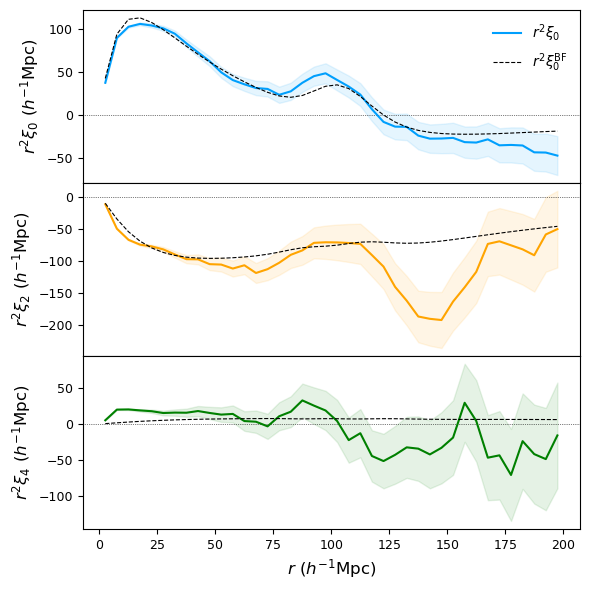

performing best fit 1st iteration ...
shape subcov (114, 114)
Best-fit parameters:
({'alpha_par': 1, 'alpha_perp': 1, 'bias': np.float64(1.6883932115744922), 'f': np.float64(0.5264343087963413), 'Sigma_par': np.float64(8.030307532226594), 'Sigma_perp': np.float64(6.060368583809912), 'Sigma_s': np.float64(0.3703725955897005), 'Sigma_rec': 0}, {'b0-2': np.float64(-1.8174400574024832), 'b0-1': np.float64(9.427758339755751), 'b00': np.float64(-16.47768987137485), 'b01': np.float64(8.587053697032497), 'b02': np.float64(1.3694159120110145), 'b2-2': np.float64(0.21403353318341897), 'b2-1': np.float64(2.919077816629054), 'b20': np.float64(-10.689540551328662), 'b21': np.float64(6.090040299066657), 'b22': np.float64(-4.40486654907133), 'b4-2': np.float64(2.0395604195823416), 'b4-1': np.float64(-8.318548674127033), 'b40': np.float64(9.922977274339162), 'b41': np.float64(-6.157017259028071), 'b42': np.float64(2.714183880092176)})
Parameter errors:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 

In [5]:
import sys
import socket
from pathlib import Path
import numpy as np

host = socket.gethostname()
print("Node:", host)
if "login" in host.lower():
    raise RuntimeError("Run this calculation on a NERSC CPU compute node.")

home = Path.home()
for directory in (
    home / "convo" / "src",
    home / "CosmoSampler",
    home / "BAOFit",
    home / "BeXiCov" / "GaussianCovariance",
    home / "BeXiCov",
):
    if directory.is_dir() and str(directory) not in sys.path:
        sys.path.insert(0, str(directory))

# BeXiCov calls the old NumPy name for trapezoidal integration.
if not hasattr(np, "trapz"):
    np.trapz = np.trapezoid

import BeXiCov.Models as Models
from BeXiCov.Covariance import BestFitCovariance

expected_models = (home / "BeXiCov" / "BeXiCov" / "Models.py").resolve()
if Path(Models.__file__).resolve() != expected_models:
    raise RuntimeError(
        f"Wrong BeXiCov import: {Models.__file__}\n"
        f"Expected: {expected_models}"
    )

base = Path("/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon")
input_path = base / "fiducial_0_snap003_xi_rsd.npz"
output_path = base / "fiducial_0_snap003_bexicov_prerec.npz"

if output_path.exists():
    raise FileExistsError(
        f"Covariance already exists; inspect it before rerunning: {output_path}"
    )

# Reload the measured multipoles. BeXiCov uses common bin centres.
with np.load(input_path, allow_pickle=False) as measurement:
    edges = np.asarray(measurement["s_edges"], dtype=float)
    xi = np.vstack([
        measurement["xi0"],
        measurement["xi2"],
        measurement["xi4"],
    ]).astype(float)
    n_halos = int(measurement["n_halos"])
    boxsize = float(measurement["boxsize"])
    redshift = float(measurement["redshift"])

s = 0.5 * (edges[:-1] + edges[1:])
volume = boxsize**3
nbar = n_halos / volume

assert np.allclose(edges, np.arange(0.0, 205.0, 5.0))
assert s.shape == (40,)
assert xi.shape == (3, 40)
assert np.all(np.isfinite(xi))
assert n_halos == 309740
assert np.isclose(boxsize, 1000.0)
assert np.isclose(redshift, 0.5)

# Reproduce the cosmology and A_s verified in your earlier CAMB cell.
cosmo = Models.DefaultCosmology()
cosmo.update({
    "Omega_m": 0.3175,
    "Omega_b": 0.049,
    "Omega_L": 1.0 - 0.3175,
    "Omega_nu": 0.0,
    "h": 0.6711,
    "ns": 0.9624,
    "As": 2.135361938993391e-9,
    "z": 0.5,
    "bias": 1.94,
    "N_eff": 3.046,
})

# For one template redshift CAMB supplies one sigma8 value in an array.
# Pass that value as a scalar to BeXiCov's no-wiggle calculation.
if not hasattr(Models, "_original_Pk_nowiggle_one_z"):
    Models._original_Pk_nowiggle_one_z = Models.Pk_nowiggle

def _Pk_nowiggle_one_z(k, pk_linear, cosmology, sigma8, T_cmb):
    values = np.asarray(sigma8)
    if values.size != 1:
        raise ValueError(f"Expected one sigma8 value, got {values.shape}")
    sigma8_scalar = float(values.reshape(-1)[0])
    if not np.isfinite(sigma8_scalar) or sigma8_scalar <= 0:
        raise ValueError(f"Invalid sigma8: {sigma8_scalar}")
    return Models._original_Pk_nowiggle_one_z(
        k, pk_linear, cosmology, sigma8_scalar, T_cmb
    )

Models.Pk_nowiggle = _Pk_nowiggle_one_z

print("Input:", input_path)
print("Halos:", n_halos)
print("2PCF shape:", xi.shape)
print("A_s:", cosmo["As"])
print("Generating BeXiCov covariance; wait for the cell to finish...")

cov_run = BestFitCovariance(
    s=s,
    xi_ell_data=xi,
    volume=volume,
    number_density=nbar,
    cosmo=cosmo,
    space="RedshiftSpace",
    rectype="",
    sigma_rec=0.0,
    ellemax=4,
    NormCov=1,
    fit_range=[10, 200],
    Niter=2,
    Use_emu=False,
)
cov_run.run()

# Audit the completed covariance before writing anything.
C_raw = np.asarray(cov_run.cov_it, dtype=float)
assert C_raw.shape == (120, 120), C_raw.shape
assert np.all(np.isfinite(C_raw))
assert np.all(np.diag(C_raw) > 0)

relative_asymmetry = (
    np.max(np.abs(C_raw - C_raw.T)) / np.max(np.abs(C_raw))
)
print("Relative asymmetry:", relative_asymmetry)
assert relative_asymmetry < 1e-10

C = 0.5 * (C_raw + C_raw.T)

fit_bins = np.flatnonzero((s >= 50) & (s <= 150))
fit_indices = np.concatenate([
    fit_bins + j * len(s) for j in range(3)
])
assert fit_bins.size == 20
assert fit_indices.size == 60
np.linalg.cholesky(C[np.ix_(fit_indices, fit_indices)])

assert np.all(np.isfinite(cov_run.best_fit_params))
if output_path.exists():
    raise FileExistsError(
        f"File appeared during calculation; not overwriting: {output_path}"
    )

np.savez_compressed(
    output_path,
    cov=C,
    s=s,
    ells=np.array([0, 2, 4]),
    volume=volume,
    number_density=nbar,
    calibration_range=np.array([10.0, 200.0]),
    planned_bao_fit_range=np.array([50.0, 150.0]),
    realization=0,
    snapshot=3,
    As=cosmo["As"],
    input_file=str(input_path),
)

print("Covariance shape:", C.shape)
print("BAO-fit submatrix shape:",
      C[np.ix_(fit_indices, fit_indices)].shape)
print("Saved covariance:", output_path)

### Step 2 result: one-mock analytical covariance

BeXiCov completed two fitting iterations using the measured
pre-reconstruction \(\xi_0,\xi_2,\xi_4\) of Quijote fiducial
realization 0. Its covariance-calibration fit used 38 separation
bins per multipole over 10–200 \(h^{-1}\mathrm{Mpc}\).

The saved covariance has shape \(120\times120\), covering all 40
measured bins for each of the three multipoles. The 50–150
\(h^{-1}\mathrm{Mpc}\) submatrix planned for the BAO fit has shape
\(60\times60\) and passed a Cholesky check. The file is
`/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_bexicov_prerec.npz`.

This establishes a usable numerical input for the one-mock BAO
pipeline test. BeXiCov printed zero parameter errors, so its
intermediate fit parameters are not reported as measured
constraints. The BAO dilation parameters have not yet been fitted.

Fitting 60 values: 20 bins each for ell = 0, 2, 4
considering  4  polynomials
fit-range [50, 150]
running fit...
modelling ...
shape subcov (60, 60)
I MnSeedGenerator Computing seed using NumericalGradient calculator


/global/homes/m/mawais/BAOFit/BAOFit/Templates.py:332: ComplexWarning: Casting complex values to real discards the imaginary part
  xi_elle[i]=(2.*elles[i]+1.)/2.*np.trapz(xi_mup_rp*Ll[:, None], x=mus, axis=0,dx=mus[1]-mus[0])


I MnSeedGenerator Evaluated function and gradient in 8.25123 s
I MnSeedGenerator Initial state: FCN =       158.6251843 Edm =       27842.68175 NCalls =     61
I NegativeG2LineSearch Doing a NegativeG2LineSearch since one of the G2 component is negative
I NegativeG2LineSearch Done after 6.35245 s
I MnSeedGenerator Negative G2 found - new state: 
  Minimum value : 85.88154069
  Edm           : 74.68753068
  Internal parameters:	[                0                0    -0.2327695674    -0.4115168461    -0.2013579208 -5.421010862e-19                0                0                0                0....                 0]	
  Internal gradient  :	[      -24.5282463     -15.04356527     -20.63428372      -94.9932713    0.04592073473      7.699641863      -0.40760474      34.30226506      76.29786433      159.2842386....       -7.19463934]	
  Internal covariance matrix:
[[    0.030972383              0              0              0              0              0              0              0  

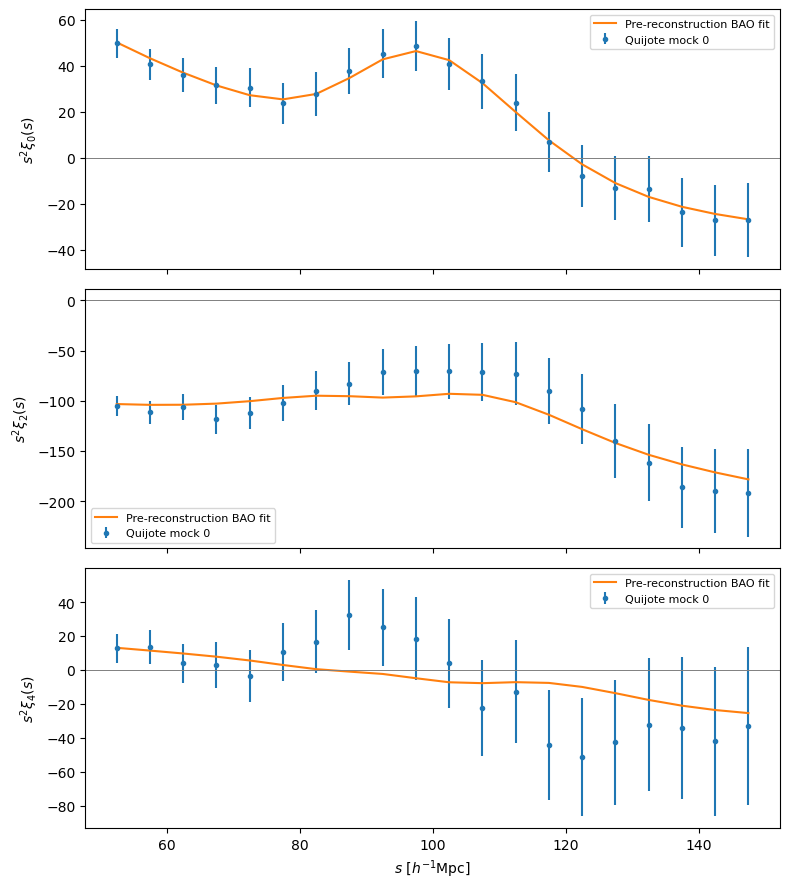

Saved fit: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_baofit_prerec.npz
Saved plot: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_baofit_prerec.png


In [6]:
from pathlib import Path
import numpy as np

# Compatibility with the NumPy version in this notebook kernel.
if not hasattr(np, "trapz"):
    np.trapz = np.trapezoid

import BAOFit.Templates as Templates
from BAOFit.Fit import BestFit

base = Path("/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon")
data_path = base / "fiducial_0_snap003_xi_rsd.npz"
cov_path = base / "fiducial_0_snap003_bexicov_prerec.npz"
fit_path = base / "fiducial_0_snap003_baofit_prerec.npz"
plot_path = base / "fiducial_0_snap003_baofit_prerec.png"

if not cov_path.is_file():
    raise FileNotFoundError(
        "The audited BeXiCov covariance has not been saved yet: "
        f"{cov_path}"
    )
if fit_path.exists() or plot_path.exists():
    raise FileExistsError(
        "A BAO fit result or plot already exists. Inspect it before rerunning."
    )
if "cosmo" not in globals():
    raise RuntimeError(
        "Run the earlier cosmology setup cell in this kernel first."
    )

# Reload the actual measurement and the audited covariance.
with np.load(data_path, allow_pickle=False) as measured:
    edges = np.asarray(measured["s_edges"], dtype=float)
    xi_data = np.vstack([
        measured["xi0"],
        measured["xi2"],
        measured["xi4"],
    ]).astype(float)
    n_halos = int(measured["n_halos"])
    redshift = float(measured["redshift"])

with np.load(cov_path, allow_pickle=False) as covariance:
    s_fit_grid = np.asarray(covariance["s"], dtype=float)
    C = np.asarray(covariance["cov"], dtype=float)
    saved_ells = np.asarray(covariance["ells"])

assert np.array_equal(saved_ells, [0, 2, 4])
assert np.allclose(edges, np.arange(0.0, 205.0, 5.0))
assert np.allclose(s_fit_grid, 0.5 * (edges[:-1] + edges[1:]))
assert xi_data.shape == (3, 40)
assert C.shape == (120, 120)
assert n_halos == 309740
assert np.isclose(redshift, 0.5)
assert np.all(np.isfinite(xi_data))
assert np.all(np.isfinite(C))
assert np.allclose(C, C.T, rtol=1e-10, atol=0)

# The CAMB template must be the same fiducial model used for covariance.
assert np.isclose(cosmo["Omega_m"], 0.3175, rtol=0, atol=1e-8)
assert np.isclose(cosmo["Omega_b"], 0.049, rtol=0, atol=1e-8)
assert np.isclose(cosmo["h"], 0.6711, rtol=0, atol=1e-8)
assert np.isclose(cosmo["z"], 0.5, rtol=0, atol=1e-8)
assert np.isclose(
    cosmo["As"], 2.135361938993391e-9, rtol=1e-5, atol=0
)

fit_mask = (s_fit_grid >= 50.0) & (s_fit_grid <= 150.0)
fit_bins = np.flatnonzero(fit_mask)
fit_indices = np.concatenate([
    fit_bins + j * len(s_fit_grid) for j in range(3)
])
assert fit_bins.size == 20
assert fit_indices.size == 60
np.linalg.cholesky(C[np.ix_(fit_indices, fit_indices)])

# BAOFit's single-redshift CAMB sigma8 has the same one-element-array
# issue previously encountered in BeXiCov. Convert only that argument.
if not hasattr(Templates, "_original_Pk_nowiggle_one_z"):
    Templates._original_Pk_nowiggle_one_z = Templates.Pk_nowiggle

def _Pk_nowiggle_one_z(k, pk_linear, cosmology, sigma8, T_cmb):
    values = np.asarray(sigma8)
    if values.size != 1:
        raise ValueError(f"Expected one sigma8 value; got {values.shape}")
    value = float(values.reshape(-1)[0])
    if not np.isfinite(value) or value <= 0:
        raise ValueError(f"Invalid sigma8: {value}")
    return Templates._original_Pk_nowiggle_one_z(
        k, pk_linear, cosmology, value, T_cmb
    )

Templates.Pk_nowiggle = _Pk_nowiggle_one_z

print("Fitting 60 values: 20 bins each for ell = 0, 2, 4")
bao_fit = BestFit(
    s=s_fit_grid,
    xi_ell_data=xi_data,
    cov=C,
    cosmo=cosmo,
    space="RedshiftSpace",
    rectype="",
    sigma_rec=0.0,
    ellemax=4,
    fit_range=[50, 150],
    FoG_opt=False,
    iso_ap=False,
    Use_emu=False,
)
bao_fit.run()
bao_fit.minuit_BF.hesse()

minuit = bao_fit.minuit_BF
names = list(bao_fit.initial_guess)
values = np.asarray(minuit.values, dtype=float)
errors = np.asarray(minuit.errors, dtype=float)
parameters = dict(zip(names, values))
uncertainties = dict(zip(names, errors))

print("Minuit valid:", minuit.valid)
print("Accurate parameter covariance:",
      minuit.fmin.has_accurate_covar)
print("Parameters at limits:",
      minuit.fmin.has_parameters_at_limit)
print("chi2 / degrees of freedom:",
      bao_fit.chi2_raw, "/", bao_fit.ndof)
for name in ("alpha_par", "alpha_perp", "bias", "f"):
    print(f"{name}: {parameters[name]:.6g} +/- "
          f"{uncertainties[name]:.6g}")

if not minuit.valid or not minuit.fmin.has_accurate_covar:
    raise RuntimeError(
        "BAO optimizer or error estimate is not valid; review its "
        "printed diagnostics before reporting a fit."
    )
if not np.all(np.isfinite(values)):
    raise RuntimeError("Non-finite best-fit parameters.")
if not all(
    np.isfinite(uncertainties[name]) and uncertainties[name] > 0
    for name in ("alpha_par", "alpha_perp")
):
    raise RuntimeError("Invalid uncertainty on a BAO dilation parameter.")

model = np.asarray(bao_fit.GetModelBF(), dtype=float)
assert model.shape == xi_data.shape
assert np.all(np.isfinite(model))

np.savez_compressed(
    fit_path,
    s=s_fit_grid,
    xi_data=xi_data,
    xi_model=model,
    parameter_names=np.asarray(names),
    parameter_values=values,
    parameter_errors=errors,
    chi2=float(bao_fit.chi2_raw),
    ndof=int(bao_fit.ndof),
    minuit_valid=bool(minuit.valid),
    accurate_parameter_covariance=bool(
        minuit.fmin.has_accurate_covar
    ),
    fit_range=np.array([50.0, 150.0]),
    ells=np.array([0, 2, 4]),
    covariance_file=str(cov_path),
)

import matplotlib.pyplot as plt

sigma_xi = np.sqrt(np.diag(C)).reshape(3, 40)
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 9))
for j, ell in enumerate((0, 2, 4)):
    axes[j].errorbar(
        s_fit_grid[fit_mask],
        s_fit_grid[fit_mask]**2 * xi_data[j, fit_mask],
        yerr=s_fit_grid[fit_mask]**2 * sigma_xi[j, fit_mask],
        fmt="o",
        ms=3,
        label="Quijote mock 0",
    )
    axes[j].plot(
        s_fit_grid[fit_mask],
        s_fit_grid[fit_mask]**2 * model[j, fit_mask],
        label="Pre-reconstruction BAO fit",
    )
    axes[j].axhline(0, color="0.5", lw=0.7)
    axes[j].set_ylabel(rf"$s^2\xi_{{{ell}}}(s)$")
    axes[j].legend(fontsize=8)

axes[-1].set_xlabel(r"$s\ [h^{-1}\mathrm{Mpc}]$")
fig.tight_layout()
fig.savefig(plot_path, dpi=180)
plt.show()

print("Saved fit:", fit_path)
print("Saved plot:", plot_path)

## Test 0: Check the pre-reconstruction BAO fit with fixed growth rate

We have measured the redshift-space 2PCF multipoles \(\xi_0\), \(\xi_2\), and \(\xi_4\) for **Quijote fiducial realization 0** at \(z=0.5\). The measurement uses a periodic box, separations from \(0\) to \(200\,h^{-1}\mathrm{Mpc}\), and bins of width \(5\,h^{-1}\mathrm{Mpc}\). We generated a one-mock analytical covariance with BeXiCov and fitted the 20 bins per multipole between \(50\) and \(150\,h^{-1}\mathrm{Mpc}\).

The first BAOFit run converged with \(\chi^2/\mathrm{dof}=50.66/45\), but its fitted growth parameter reached the allowed upper bound, \(f\simeq2\). It returned \(\alpha_\parallel=1.0108\pm0.0520\) and \(\alpha_\perp=1.0571\pm0.0153\). We therefore check how sensitive the BAO fit is to the treatment of \(f\) before interpreting these parameter errors.

In the next cell, we **repeat the same fit using the same measured multipoles, covariance, and fitting range**, while fixing \(f=0.762579\), our previously calculated approximate fiducial growth-rate benchmark at \(z=0.5\). We compare the new \(\alpha_\parallel\), \(\alpha_\perp\), \(\chi^2\), and parameter-limit flags with the original run. The result is saved separately with the suffix `_f_fixed`.

**Interpretation:** Fixing \(f\) is a sensitivity check for the BAO fit. It does not measure the growth rate or complete the separate velocity/RSD check. We will assess the outcome after the next cell has finished.

BAOFit source: /global/homes/m/mawais/BAOFit/BAOFit/Fit.py
2PCF input: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_xi_rsd.npz
Covariance input: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_bexicov_prerec.npz
Selected covariance field: cov
Halos in measurement: 309740
Fit bins per multipole: 20
Fixed f: 0.762579
Starting fixed-f BAO fit...
considering  4  polynomials
fit-range [50.0, 150.0]
using default Neff 3.046
running fit...
modelling ...
shape subcov (60, 60)
I MnSeedGenerator Computing seed using NumericalGradient calculator
I MnSeedGenerator Evaluated function and gradient in 7.62679 s
I MnSeedGenerator Initial state: FCN =       137.7649053 Edm =       27288.34936 NCalls =     57
I NegativeG2LineSearch Doing a NegativeG2LineSearch since one of the G2 component is negative
I NegativeG2LineSearch Done after 5.6317 s
I MnSeedGenerator Negative G2 found - new state: 
  Minimum value : 74.10575981
  Edm           : 25.33555959
  Inter

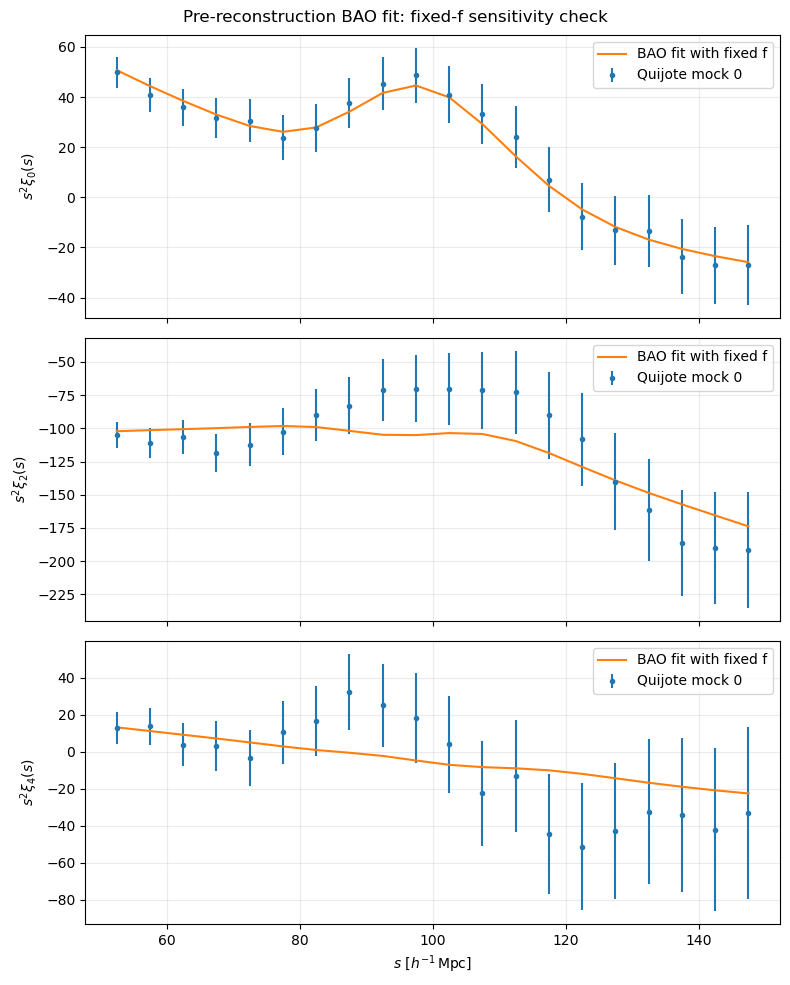

Saved check plot: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_baofit_prerec_f_fixed.png


In [8]:
# Test 0: BAO fit sensitivity check with f fixed
# This checks whether the BAO parameters change when f cannot run
# to the upper limit seen in our original free-f fit.

from pathlib import Path
import sys
import numpy as np

# Compatibility with NumPy 2.x used by this notebook.
if not hasattr(np, "trapz"):
    np.trapz = np.trapezoid

# Use the BAOFit and dependency clones already present in NERSC home.
home = Path.home()
for package_dir in (home / "convo" / "src",
                    home / "CosmoSampler",
                    home / "BAOFit"):
    if package_dir.is_dir():
        sys.path.insert(0, str(package_dir))

import BAOFit.Templates as Templates
from BAOFit.Fit import BestFit, DefaultPriors
from BAOFit.utils import DefaultCosmology

# BAOFit passes a one-element sigma8 array to a routine that expects
# a scalar. Apply the same in-memory compatibility fix used previously.
_original_pk_nowiggle = Templates.Pk_nowiggle

def pk_nowiggle_scalar_sigma8(k, pk_linear, cosmology, sigma8, t_cmb):
    sigma8_array = np.asarray(sigma8)
    if sigma8_array.size != 1:
        raise ValueError(f"Expected one sigma8 value; got shape {sigma8_array.shape}")
    return _original_pk_nowiggle(
        k, pk_linear, cosmology, float(sigma8_array.item()), t_cmb
    )

# Avoid wrapping the function twice if the cell is rerun.
if not getattr(Templates.Pk_nowiggle, "_scalar_sigma8_fix", False):
    pk_nowiggle_scalar_sigma8._scalar_sigma8_fix = True
    Templates.Pk_nowiggle = pk_nowiggle_scalar_sigma8

base = Path("/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon")
xi_path = base / "fiducial_0_snap003_xi_rsd.npz"
cov_path = base / "fiducial_0_snap003_bexicov_prerec.npz"

for path in (xi_path, cov_path):
    if not path.is_file():
        raise FileNotFoundError(f"Required input is missing: {path}")

# Read the measured multipoles. Use the fixed bin centres that were
# used for the original BAO fit, rather than the pair-averaged s values.
with np.load(xi_path, allow_pickle=False) as data:
    required = {"s_edges", "xi0", "xi2", "xi4"}
    missing = required.difference(data.files)
    if missing:
        raise KeyError(f"Missing fields in 2PCF file: {sorted(missing)}")

    s_edges = np.asarray(data["s_edges"], dtype=float)
    xi = np.stack(
        [np.asarray(data[key], dtype=float)
         for key in ("xi0", "xi2", "xi4")]
    )
    n_halos = int(data["n_halos"]) if "n_halos" in data.files else None

if not np.allclose(s_edges, np.arange(0.0, 205.0, 5.0)):
    raise ValueError("Separation edges are not 0–200 Mpc/h in 5 Mpc/h bins.")

s = 0.5 * (s_edges[:-1] + s_edges[1:])

if xi.shape != (3, 40) or not np.all(np.isfinite(xi)):
    raise ValueError(f"Unexpected 2PCF shape or non-finite data: {xi.shape}")

# Select the saved FULL BeXiCov covariance, not a correlation matrix
# or a preselected fit submatrix. Print the key for the notebook record.
with np.load(cov_path, allow_pickle=False) as data:
    candidates = {}
    for key in data.files:
        try:
            array = np.asarray(data[key])
        except ValueError:
            continue
        if array.shape == (120, 120) and np.issubdtype(array.dtype, np.number):
            candidates[key] = np.asarray(array, dtype=float)

    if not candidates:
        raise KeyError(
            f"No 120 x 120 numeric covariance found. Fields: {data.files}"
        )

    preferred = ("cov_it", "cov", "covariance", "cov_full",
                 "C_raw", "C")
    chosen = next((key for key in preferred if key in candidates), None)

    if chosen is None:
        non_correlation = [
            key for key in candidates if "corr" not in key.lower()
        ]
        if len(non_correlation) != 1:
            raise ValueError(
                "Cannot uniquely identify the final covariance. "
                f"120 x 120 fields: {list(candidates)}"
            )
        chosen = non_correlation[0]

    cov = candidates[chosen]

if not np.all(np.isfinite(cov)):
    raise ValueError("Covariance contains non-finite values.")
if not np.allclose(cov, cov.T, rtol=1e-7, atol=1e-15):
    raise ValueError("Covariance is not symmetric.")
if not np.all(np.diag(cov) > 0):
    raise ValueError("Covariance has non-positive diagonal entries.")

fit_mask = (s >= 50.0) & (s <= 150.0)
fit_indices = np.concatenate([
    np.flatnonzero(fit_mask) + ell_index * 40
    for ell_index in range(3)
])
fit_cov = cov[np.ix_(fit_indices, fit_indices)]

if fit_cov.shape != (60, 60):
    raise ValueError(f"Unexpected fit covariance shape: {fit_cov.shape}")
np.linalg.cholesky(fit_cov)  # Raises an error if it is not positive definite.

# The same Quijote fiducial template cosmology as in the previous fit.
cosmo = DefaultCosmology()
cosmo.update({
    "Omega_m": 0.3175,
    "Omega_b": 0.049,
    "Omega_nu": 0.0,
    "Omega_L": 1.0 - 0.3175,
    "h": 0.6711,
    "ns": 0.9624,
    "As": 2.135361938993391e-9,  # Previously calibrated to sigma8(z=0)=0.834
    "z": 0.5,
})

# Fix f to the previously calculated fiducial growth-rate benchmark.
# This is an ASSUMPTION for a BAO sensitivity check, not a measurement of f.
f_fixed = 0.762579
priors = dict(DefaultPriors)
priors["f"] = f_fixed

print("BAOFit source:", Path(sys.modules["BAOFit.Fit"].__file__))
print("2PCF input:", xi_path)
print("Covariance input:", cov_path)
print("Selected covariance field:", chosen)
print("Halos in measurement:", n_halos)
print("Fit bins per multipole:", int(fit_mask.sum()))
print("Fixed f:", f_fixed)
print("Starting fixed-f BAO fit...")

bao_fit = BestFit(
    s=s,
    xi_ell_data=xi,
    cov=cov,
    cosmo=cosmo,
    space="RedshiftSpace",
    rectype="",                 # Pre-reconstruction
    sigma_rec=0.0,
    ellemax=4,                 # Fit ell = 0, 2, 4
    fit_range=[50.0, 150.0],
    FoG_opt=False,             # Same setting as the original fit
    iso_ap=False,              # Fit alpha_par and alpha_perp
    Priors=priors,
    Use_emu=False,
)

bao_fit.run()
bao_fit.minuit_BF.hesse()

minuit = bao_fit.minuit_BF
physical, broadband = bao_fit.GetParBF()
parameter_names = list(bao_fit.initial_guess)
parameter_errors = dict(zip(parameter_names, minuit.errors))

print("\n=== FIXED-f FIT CHECK ===")
print("Minuit valid:", minuit.fmin.is_valid)
print("Accurate parameter covariance:", minuit.fmin.has_accurate_covar)
print("Parameters at limits:", minuit.fmin.has_parameters_at_limit)
print(f"chi2 / dof: {bao_fit.chi2_raw:.5f} / {bao_fit.ndof}")
print(f"alpha_par:  {physical['alpha_par']:.6f} +/- "
      f"{parameter_errors['alpha_par']:.6f}")
print(f"alpha_perp: {physical['alpha_perp']:.6f} +/- "
      f"{parameter_errors['alpha_perp']:.6f}")
print(f"f: {physical['f']:.6f} (fixed, not measured)")
print("Damping parameters:",
      {key: physical[key] for key in ("Sigma_par", "Sigma_perp", "Sigma_s")})

# Direct comparison with the original free-f result printed in your log.
print("\nChange relative to original free-f fit:")
print(f"alpha_par:  {physical['alpha_par'] - 1.0108071531976495:+.6f}")
print(f"alpha_perp: {physical['alpha_perp'] - 1.0571079170124293:+.6f}")
print(f"chi2:       {bao_fit.chi2_raw - 50.66134248424026:+.5f}")
print("Note: the fixed-f fit has one fewer free parameter.")

model = np.asarray(bao_fit.GetModelBF(), dtype=float)
if model.shape != (3, 40) or not np.all(np.isfinite(model)):
    raise ValueError(f"Unexpected fitted-model shape or values: {model.shape}")

result_path = base / "fiducial_0_snap003_baofit_prerec_f_fixed.npz"
np.savez_compressed(
    result_path,
    s=s,
    s_edges=s_edges,
    xi=xi,
    xi_model=model,
    covariance_key=np.asarray(chosen),
    f_fixed=np.asarray(f_fixed),
    alpha_par=np.asarray(physical["alpha_par"]),
    alpha_par_error=np.asarray(parameter_errors["alpha_par"]),
    alpha_perp=np.asarray(physical["alpha_perp"]),
    alpha_perp_error=np.asarray(parameter_errors["alpha_perp"]),
    chi2=np.asarray(bao_fit.chi2_raw),
    ndof=np.asarray(bao_fit.ndof),
    minuit_valid=np.asarray(minuit.fmin.is_valid),
    accurate_parameter_covariance=np.asarray(minuit.fmin.has_accurate_covar),
    parameters_at_limits=np.asarray(minuit.fmin.has_parameters_at_limit),
)
print("\nSaved fixed-f check:", result_path)

# Show the measured points, marginal covariance errors, and fitted model
# within the actual fitting range only.
import matplotlib.pyplot as plt

sigma_xi = np.sqrt(np.diag(cov)).reshape(3, 40)
fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

for index, (ax, ell) in enumerate(zip(axes, (0, 2, 4))):
    x = s[fit_mask]
    ax.errorbar(
        x,
        x**2 * xi[index, fit_mask],
        yerr=x**2 * sigma_xi[index, fit_mask],
        fmt="o", ms=3, capsize=0, label="Quijote mock 0"
    )
    ax.plot(
        x, x**2 * model[index, fit_mask],
        color="tab:orange", label="BAO fit with fixed f"
    )
    ax.set_ylabel(rf"$s^2\xi_{{{ell}}}(s)$")
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].set_xlabel(r"$s\ [h^{-1}\,\mathrm{Mpc}]$")
fig.suptitle("Pre-reconstruction BAO fit: fixed-f sensitivity check")
fig.tight_layout()

plot_path = base / "fiducial_0_snap003_baofit_prerec_f_fixed.png"
fig.savefig(plot_path, dpi=180)
plt.show()
print("Saved check plot:", plot_path)

Saved arrays: ['cov', 's', 'ells', 'volume', 'number_density', 'calibration_range', 'planned_bao_fit_range', 'realization', 'snapshot', 'As', 'input_file']


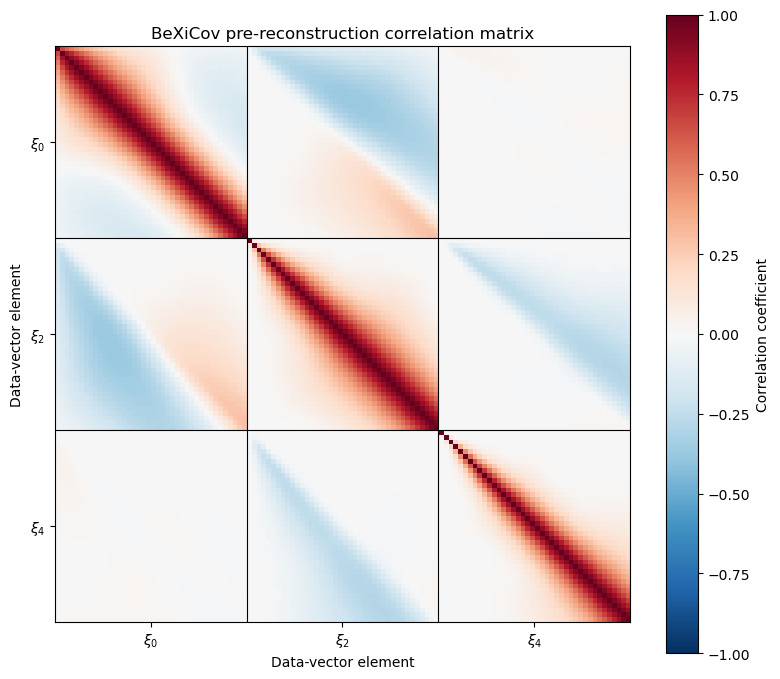

Covariance shape: (120, 120)
Correlation diagonal range: 0.9999999999999998 1.0000000000000002


In [10]:
import numpy as np
import matplotlib.pyplot as plt

path = "/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_bexicov_prerec.npz"

with np.load(path) as archive:
    print("Saved arrays:", archive.files)
    C = np.asarray(archive["cov"], dtype=float)

assert C.ndim == 2 and C.shape[0] == C.shape[1], C.shape
assert np.all(np.isfinite(C)), "Covariance contains non-finite values"
assert np.all(np.diag(C) > 0), "Covariance has a non-positive diagonal"

sigma = np.sqrt(np.diag(C))
R = C / np.outer(sigma, sigma)

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1, origin="upper")
fig.colorbar(image, ax=ax, label="Correlation coefficient")

if C.shape == (120, 120):
    for boundary in (39.5, 79.5):
        ax.axhline(boundary, color="black", lw=0.8)
        ax.axvline(boundary, color="black", lw=0.8)
    ax.set_xticks([19.5, 59.5, 99.5], [r"$\xi_0$", r"$\xi_2$", r"$\xi_4$"])
    ax.set_yticks([19.5, 59.5, 99.5], [r"$\xi_0$", r"$\xi_2$", r"$\xi_4$"])

ax.set_title("BeXiCov pre-reconstruction correlation matrix")
ax.set_xlabel("Data-vector element")
ax.set_ylabel("Data-vector element")
plt.tight_layout()
plt.show()

print("Covariance shape:", C.shape)
print("Correlation diagonal range:", np.diag(R).min(), np.diag(R).max())

In [12]:
import sys
from pathlib import Path

import numpy as np
import camb
from iminuit import Minuit
from pypower import CatalogFFTPower

sys.path.insert(0, "/global/homes/m/mawais/quijote_tools")
import readfof

# Quijote fiducial realization 0, snapshot 003 (z = 0.5)
z = 0.5
boxsize = 1000.0                         # Mpc/h
omega_m, omega_b, h = 0.3175, 0.049, 0.6711
H_over_h = 100.0 * np.sqrt(
    omega_m * (1.0 + z)**3 + 1.0 - omega_m
)                                        # km/s/(Mpc/h)

fof = readfof.FoF_catalog(
    "/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0",
    3,
    long_ids=False, swap=False, SFR=False, read_IDs=False,
)
keep = np.asarray(fof.GroupLen) >= 20
real_positions = np.asarray(fof.GroupPos[keep], dtype=np.float64) / 1000.0

# GroupVel is NOT yet the peculiar velocity in km/s.
velocity_kms = np.asarray(fof.GroupVel[keep], dtype=np.float64) * (1.0 + z)
dz = velocity_kms[:, 2] * (1.0 + z) / H_over_h

redshift_positions = real_positions.copy()
redshift_positions[:, 2] = (real_positions[:, 2] + dz) % boxsize

n_halos = len(real_positions)
nbar = n_halos / boxsize**3
median_dz = np.median(np.abs(dz))
max_dz = np.max(np.abs(dz))

print("Halos:", n_halos)
print("Median/max |z displacement| [Mpc/h]:", median_dz, max_dz)
assert n_halos == 309740
assert np.isclose(median_dz, 2.278162, rtol=0.02), (
    "STOP: displacement does not match the earlier 2PCF run"
)

# Measure the same k bins in real space and redshift space.
k_edges = np.linspace(0.0, 0.10, 11)     # h/Mpc

def measure_poles(positions, label):
    print("Measuring", label, "P0, P2...", flush=True)
    result = CatalogFFTPower(
        data_positions1=[positions[:, i] for i in range(3)],
        position_type="xyz",
        edges=k_edges,
        ells=(0, 2),
        los="z",
        boxsize=boxsize,
        boxcenter=(500.0, 500.0, 500.0),
        nmesh=256,
        resampler="tsc",
        interlacing=2,
        wrap=True,
    )
    return (
        np.asarray(result.poles.k, dtype=float),
        np.asarray(
            result.poles.get_power(remove_shotnoise=True, complex=False),
            dtype=float,
        ),
    )

k, power_real = measure_poles(real_positions, "real-space")
k_rsd, power_rsd = measure_poles(redshift_positions, "redshift-space")
assert np.allclose(k, k_rsd)
assert power_real.shape == power_rsd.shape == (2, 10)

# Linear matter spectrum and growth rate for the same fiducial cosmology.
pars = camb.CAMBparams()
pars.set_cosmology(
    H0=100.0 * h,
    ombh2=omega_b * h**2,
    omch2=(omega_m - omega_b) * h**2,
    mnu=0.0,
    omk=0.0,
    tau=0.06,
)
pars.InitPower.set_params(As=2.135361938993391e-9, ns=0.9624)
pars.set_matter_power(redshifts=[z], kmax=0.3)

camb_results = camb.get_results(pars)
sigma8_z = float(camb_results.get_sigma8()[0])
f_theory = float(camb_results.get_fsigma8()[0] / sigma8_z)
pk_interp = camb_results.get_matter_power_interpolator(
    nonlinear=False, hubble_units=True, k_hunit=True
)
pk_matter = np.asarray(pk_interp.P(z, k), dtype=float)

print("CAMB fiducial f(z=0.5):", f_theory)

# Pilot linear-Kaiser fit, with an approximate Gaussian covariance
# evaluated once at reference b and f. Errors are diagnostic.
mu, mu_weights = np.polynomial.legendre.leggauss(64)
L = np.vstack((np.ones_like(mu), 0.5 * (3.0 * mu**2 - 1.0)))
ell_factors = np.array([1.0, 5.0])

cov_inv = []
b_reference = 1.94
for i in range(len(k)):
    nmodes = boxsize**3 * (k_edges[i+1]**3 - k_edges[i]**3) / (
        6.0 * np.pi**2
    )
    signal_plus_noise = (
        (b_reference + f_theory * mu**2)**2 * pk_matter[i] + 1.0 / nbar
    )
    angular = np.einsum(
        "m,im,jm,m->ij",
        mu_weights / 2.0,
        L, L,
        signal_plus_noise**2,
    )
    covariance = (
        2.0 * np.outer(ell_factors, ell_factors) * angular / nmodes
    )
    cov_inv.append(np.linalg.inv(covariance))
cov_inv = np.asarray(cov_inv)

fit_rows = []
for kmax in (0.06, 0.08, 0.10):
    selected = np.flatnonzero(
        (k >= 0.02) & (k < kmax - 1e-10)
    )

    def chi2(b, f):
        model_p0 = (
            b**2 + (2.0/3.0)*b*f + (1.0/5.0)*f**2
        ) * pk_matter[selected]
        model_p2 = (
            (4.0/3.0)*b*f + (4.0/7.0)*f**2
        ) * pk_matter[selected]

        residual = np.stack((
            power_rsd[0, selected] - model_p0,
            power_rsd[1, selected] - model_p2,
        ), axis=1)

        return float(np.einsum(
            "ki,kij,kj->", residual, cov_inv[selected], residual
        ))

    fit = Minuit(chi2, b=1.94, f=f_theory)
    fit.errordef = Minuit.LEAST_SQUARES
    fit.limits["b"] = (0.1, 5.0)
    fit.limits["f"] = (0.0, 2.0)
    fit.migrad()
    fit.hesse()

    dof = 2 * len(selected) - 2
    fit_rows.append([
        kmax, fit.values["b"], fit.errors["b"],
        fit.values["f"], fit.errors["f"],
        fit.fval, dof,
        int(fit.valid), int(fit.accurate),
        int(fit.fmin.has_parameters_at_limit),
    ])
    print(
        f"0.02 <= k < {kmax:.2f} h/Mpc: "
        f"b={fit.values['b']:.4f} +/- {fit.errors['b']:.4f}, "
        f"f={fit.values['f']:.4f} +/- {fit.errors['f']:.4f}, "
        f"chi2/dof={fit.fval:.2f}/{dof}; "
        f"valid={fit.valid}, accurate_cov={fit.accurate}, "
        f"at_limit={fit.fmin.has_parameters_at_limit}"
    )

output = Path(
    "/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/"
    "fiducial_0_growth_rsd_corrected_velocity.npz"
)
np.savez_compressed(
    output,
    k=k,
    k_edges=k_edges,
    power_real=power_real,
    power_rsd=power_rsd,
    pk_matter=pk_matter,
    fit_rows=np.asarray(fit_rows, dtype=float),
    f_theory=f_theory,
    sigma8_z=sigma8_z,
    n_halos=n_halos,
    nbar=nbar,
    median_abs_dz=median_dz,
    max_abs_dz=max_dz,
)
print("Saved corrected velocity check:", output)

Halos: 309740
Median/max |z displacement| [Mpc/h]: 2.2781620237531657 23.519658127077907
Measuring real-space P0, P2...
Measuring redshift-space P0, P2...
CAMB fiducial f(z=0.5): 0.762786194465871
0.02 <= k < 0.06 h/Mpc: b=1.9246 +/- 0.0409, f=0.7952 +/- 0.1023, chi2/dof=6.31/6; valid=True, accurate_cov=True, at_limit=False
0.02 <= k < 0.08 h/Mpc: b=1.9025 +/- 0.0269, f=0.8747 +/- 0.0663, chi2/dof=9.70/10; valid=True, accurate_cov=True, at_limit=False
0.02 <= k < 0.10 h/Mpc: b=1.9326 +/- 0.0196, f=0.7969 +/- 0.0486, chi2/dof=14.49/14; valid=True, accurate_cov=True, at_limit=False
Saved corrected velocity check: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_growth_rsd_corrected_velocity.npz


In [4]:
from pathlib import Path
Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/1/groups_003").mkdir(
    parents=True, exist_ok=True
)

### Step 4 — Verify realization 1

Globus reported that the snapshot `003` FoF catalogue for fiducial realization 1 transferred successfully. We now check that the catalogue file is present and nonempty in its NERSC scratch directory. This step does not measure the 2PCF yet.

In [5]:
from pathlib import Path

folder = Path(
    "/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/1/groups_003"
)
parts = sorted(folder.glob("group_tab_003.*"))

print("Catalogue directory:", folder)
print("Catalogue parts found:", len(parts))

for part in parts:
    print(part.name, part.stat().st_size, "bytes")

assert parts, "No catalogue parts found at the destination"
assert all(part.stat().st_size > 0 for part in parts), "An empty file was found"
print("Realization 1 file check passed.")

Catalogue directory: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/1/groups_003
Catalogue parts found: 1
group_tab_003.0 26077152 bytes
Realization 1 file check passed.


### Step 5 — Transfer the remaining eight catalogues

Realizations 0 and 1 have been transferred and checked. We will now transfer snapshot `003` from fiducial realizations 2–9. Each realization must go into the NERSC folder with the same number. We will measure their 2PCFs only after all catalogue files are present.

In [11]:
from pathlib import Path

root = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial")

for i in range(2, 10):
    destination = root / str(i) / "groups_003"
    destination.mkdir(parents=True, exist_ok=True)
    print(f"Realization {i}: {destination}")

Realization 2: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/2/groups_003
Realization 3: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/3/groups_003
Realization 4: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/4/groups_003
Realization 5: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/5/groups_003
Realization 6: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/6/groups_003
Realization 7: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/7/groups_003
Realization 8: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/8/groups_003
Realization 9: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/9/groups_003


### Step 6 — Check all ten transferred catalogues

We check that realizations 0–9 each have at least one nonempty snapshot `003` FoF catalogue part in the correct NERSC folder. This checks file presence and size; we will check that `readfof` can read each catalogue during the measurement step.

### Step 7 — Verify the ten selected FoF catalogues

We check that each selected fiducial realization has a nonempty snapshot `003` catalogue in its own NERSC scratch folder. This is a file-transfer check; reading and measuring the catalogues comes next.

In [34]:
from pathlib import Path

root = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial")
ids = (0, 1, 10, 100, 1000, 10000, 10001, 10002, 10003, 10004)

ready = 0
for i in ids:
    expected = root / str(i) / "groups_003" / "group_tab_003.0"
    one_level_high = root / str(i) / "group_tab_003.0"

    if expected.is_file() and expected.stat().st_size > 0:
        ready += 1
        print(f"{i}: READY — {expected.stat().st_size:,} bytes")
    elif one_level_high.is_file():
        print(f"{i}: ONE FOLDER TOO HIGH — {one_level_high}")
    else:
        print(f"{i}: MISSING from expected location")

print(f"\nReady: {ready}/10")

0: READY — 26,018,184 bytes
1: READY — 26,077,152 bytes
10: READY — 25,961,148 bytes
100: READY — 25,954,512 bytes
1000: READY — 25,926,120 bytes
10000: READY — 26,043,132 bytes
10001: READY — 25,949,808 bytes
10002: READY — 23,068,672 bytes
10003: READY — 26,060,352 bytes
10004: READY — 25,940,232 bytes

Ready: 10/10


In [36]:
from pathlib import Path
import struct

root = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial")
ids = (0, 1, 10, 100, 1000, 10000, 10001, 10002, 10003, 10004)

passed = 0

for i in ids:
    file = root / str(i) / "groups_003" / "group_tab_003.0"

    if not file.is_file():
        print(f"{i}: MISSING")
        continue

    actual = file.stat().st_size
    with file.open("rb") as f:
        header = f.read(24)

    if len(header) != 24:
        print(f"{i}: INCOMPLETE HEADER — {actual:,} bytes")
        continue

    n_groups, total_groups, n_ids, total_ids, n_files = struct.unpack(
        "<iiiQI", header
    )
    expected = 24 + 84 * n_groups

    if n_files != 1 or n_groups != total_groups:
        status = "CHECK PARTS/HEADER"
    elif actual == expected:
        status = "COMPLETE"
        passed += 1
    elif actual < expected:
        status = "INCOMPLETE UPLOAD"
    else:
        status = "UNEXPECTED SIZE"

    print(
        f"{i}: {status} | halos={n_groups:,} | "
        f"actual={actual:,} | expected={expected:,} bytes | parts={n_files}"
    )

print(f"\nComplete single-part catalogues: {passed}/10")

0: COMPLETE | halos=309,740 | actual=26,018,184 | expected=26,018,184 bytes | parts=1
1: COMPLETE | halos=310,442 | actual=26,077,152 | expected=26,077,152 bytes | parts=1
10: COMPLETE | halos=309,061 | actual=25,961,148 | expected=25,961,148 bytes | parts=1
100: COMPLETE | halos=308,982 | actual=25,954,512 | expected=25,954,512 bytes | parts=1
1000: COMPLETE | halos=308,644 | actual=25,926,120 | expected=25,926,120 bytes | parts=1
10000: COMPLETE | halos=310,037 | actual=26,043,132 | expected=26,043,132 bytes | parts=1
10001: COMPLETE | halos=308,926 | actual=25,949,808 | expected=25,949,808 bytes | parts=1
10002: COMPLETE | halos=308,529 | actual=25,916,460 | expected=25,916,460 bytes | parts=1
10003: COMPLETE | halos=310,242 | actual=26,060,352 | expected=26,060,352 bytes | parts=1
10004: COMPLETE | halos=308,812 | actual=25,940,232 | expected=25,940,232 bytes | parts=1

Complete single-part catalogues: 10/10
